# Assignment 2: Self-Supervised Representation Learning

## 0. Setup

In [13]:
import subprocess, sys
from pathlib import Path

import torch

DATA_ROOT = Path('data')       # contains train/<class>/ and test/<class>/  (edit for your machine)
RUNS_DIR = Path('runs')
FIGS = Path('figures')

print(f'PyTorch {torch.__version__} | CUDA {torch.cuda.is_available()}'
      + (f' | {torch.cuda.get_device_name(0)}' if torch.cuda.is_available() else ''))
assert (DATA_ROOT / 'train').exists(), f'put the dataset under {DATA_ROOT.resolve()}'


def run(script, config, name, *sets, force=False):
    """Run a training script with the same Python as this kernel and stream its output."""
    cmd = [sys.executable, '-u', script, '--config', f'configs/{config}.yaml', '--name', name,
           '--set', f'data_root={DATA_ROOT.as_posix()}', f'runs_dir={RUNS_DIR.as_posix()}', *sets]
    if force:
        cmd.append('--force')
    print('$', ' '.join(cmd[1:]), flush=True)
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line, end='', flush=True)
    if p.wait() != 0:
        raise RuntimeError(f'{name} failed (exit code {p.returncode})')

PyTorch 2.6.0+cu124 | CUDA True | NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Data and augmentations

Building image cache data\cache_144.pt ...
16 classes | train 1920 | val 480 | test 400
['Bedroom', 'Coast', 'Flower', 'Forest', 'Highway', 'Industrial', 'InsideCity', 'Kitchen', 'LivingRoom', 'Mountain', 'Office', 'OpenCountry', 'Store', 'Street', 'Suburb', 'TallBuilding']


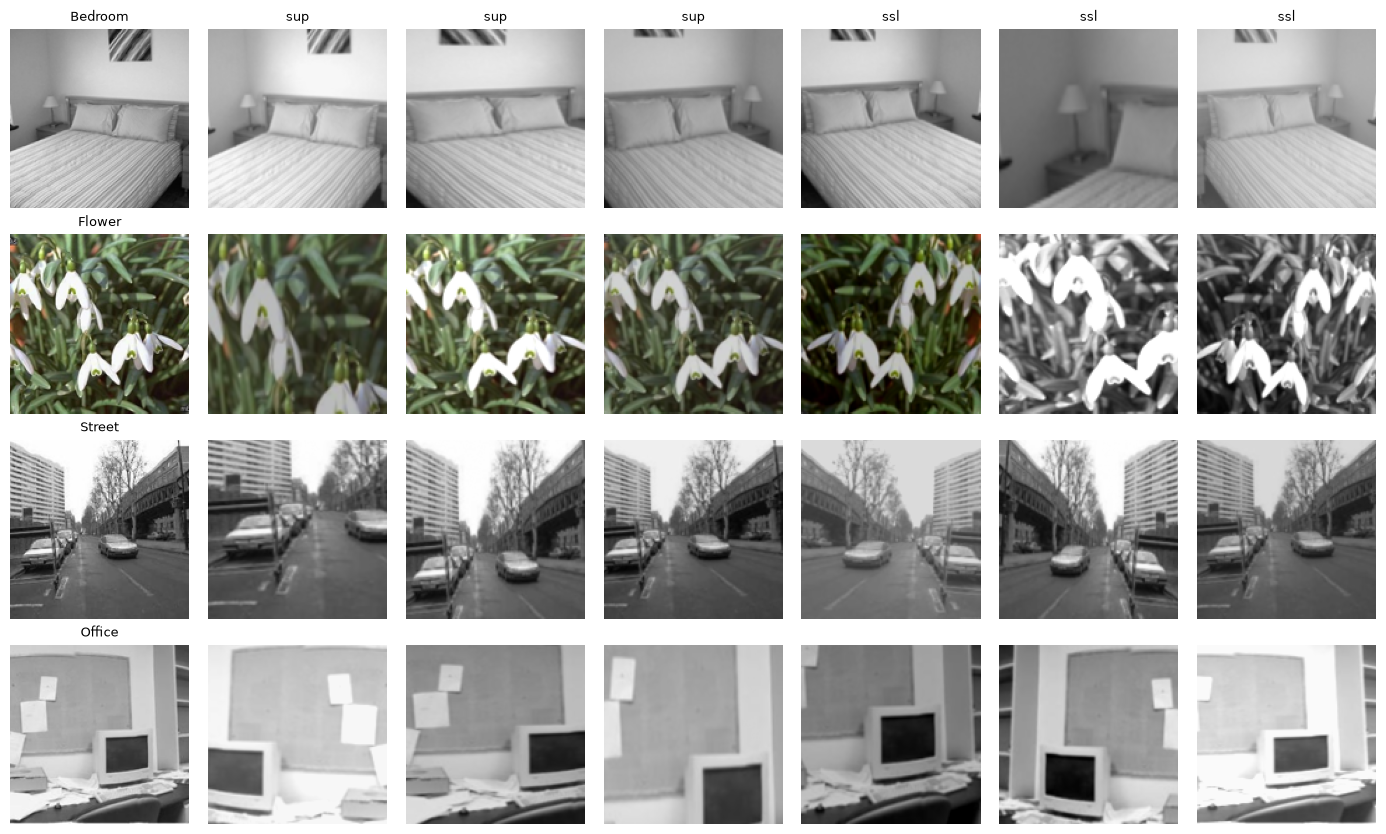

In [4]:
import matplotlib.pyplot as plt
import plots
from augment import PRESETS, augment, denormalize
from common import DEFAULTS, load_data

cfg = dict(DEFAULTS, data_root=str(DATA_ROOT))
data = load_data(cfg)
classes = data['classes']
print(f"{len(classes)} classes | train {len(data['y_train'])} | val {len(data['y_val'])} | test {len(data['y_test'])}")
print(classes)

torch.manual_seed(1)
idx = [0, 300, 700, 1100]
fig, axes = plt.subplots(len(idx), 7, figsize=(14, 2.1 * len(idx)))
for r, i in enumerate(idx):
    x = data['x_train'][i:i + 1].repeat(3, 1, 1, 1)
    views = [x[:1].float() / 255] + [denormalize(v) for v in augment(x, PRESETS['sup'], 128)] \
            + [denormalize(v) for v in augment(x, PRESETS['ssl'], 128)]
    for c, v in enumerate(views):
        axes[r, c].imshow(v.squeeze(0).permute(1, 2, 0)); axes[r, c].axis('off')
    axes[r, 0].set_title(classes[data['y_train'][i]], fontsize=9)
for c, t in enumerate(['original'] + ['sup'] * 3 + ['ssl'] * 3):
    if c: axes[0, c].set_title(t, fontsize=9)
plt.tight_layout(); FIGS.mkdir(exist_ok=True); plt.savefig(FIGS / 'augmentations.png', dpi=120); plt.show()

## 2. Supervised baseline

$ -u train.py --config configs/supervised.yaml --name sup_baseline --set data_root=data runs_dir=runs
sup_baseline | scratch | resnet18 | 1920 labelled imgs | 3000 steps bs 128 | trainable 11.18M | aug={'scale_min': 0.35, 'scale_max': 1.0, 'flip': True, 'jitter': 0.2, 'hue': 0.0, 'jitter_p': 0.8, 'gray_p': 0.0}
time_s=23.5000  step=150  lr=0.1000  train_loss=1.8204  train_acc_aug=0.3953  train_loss_clean=1.2268  train_acc_clean=0.5750  val_loss=1.4867  val_acc=0.5438
time_s=46.3000  step=300  lr=0.0993  train_loss=0.9246  train_acc_aug=0.6901  train_loss_clean=0.9746  train_acc_clean=0.6760  val_loss=1.4386  val_acc=0.5667
time_s=69.8000  step=450  lr=0.0973  train_loss=0.5902  train_acc_aug=0.7997  train_loss_clean=0.5383  train_acc_clean=0.8115  val_loss=1.1847  val_acc=0.6292
time_s=93.8000  step=600  lr=0.0940  train_loss=0.4147  train_acc_aug=0.8603  train_loss_clean=0.2747  train_acc_clean=0.9120  val_loss=1.0933  val_acc=0.6875
time_s=118.1000  step=750  lr=0.0895  train_loss=0.

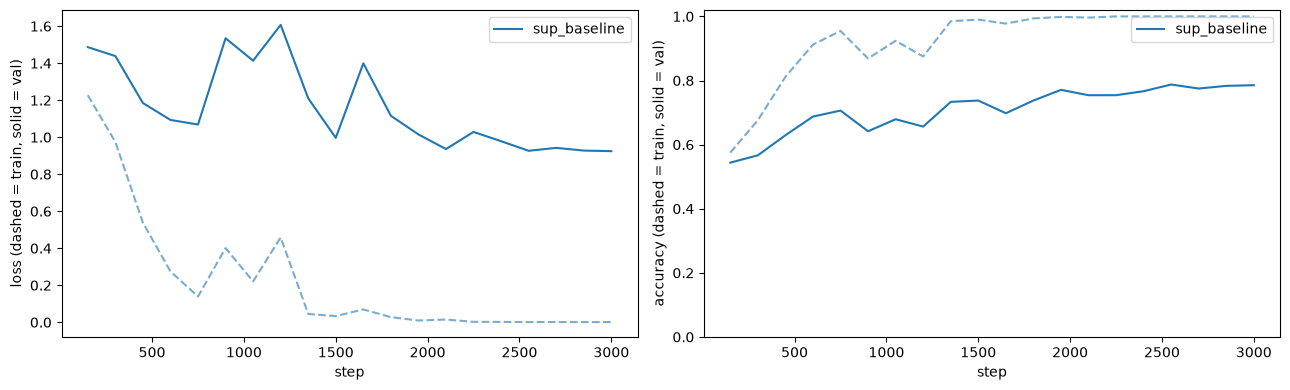

,labels,val,test,test+TTA,train(clean),gap,kNN val,min
method,,,,,,,,
sup_baseline,1920,78.5,76.0,75.5,100.0,21.5,-,8.3


In [5]:
run('train.py', 'supervised', 'sup_baseline')
plots.curves(['sup_baseline'], RUNS_DIR, save=FIGS / 'exp1_baseline.png')
plots.table(['sup_baseline'], RUNS_DIR)

## 3. SimCLR pretraining

$ -u pretrain_ssl.py --config configs/simclr.yaml --name simclr --set data_root=data runs_dir=runs
SimCLR | resnet18 | 1920 unlabeled images | bs 256 | 500 epochs (3500 steps) | T=0.2 | aug={'scale_min': 0.2, 'scale_max': 1.0, 'flip': True, 'jitter': 0.4, 'hue': 0.1, 'jitter_p': 0.8, 'gray_p': 0.2}
time_s=5.6000  epoch=1  step=7  lr=0.0200  ssl_loss=6.0216  knn_val_acc=0.3104
time_s=115.5000  epoch=25  step=175  lr=0.1995  ssl_loss=3.3207  knn_val_acc=0.5333
time_s=233.8000  epoch=50  step=350  lr=0.1968  ssl_loss=2.8927  knn_val_acc=0.6063
time_s=359.2000  epoch=75  step=525  lr=0.1915  ssl_loss=2.6900  knn_val_acc=0.6604
time_s=486.7000  epoch=100  step=700  lr=0.1839  ssl_loss=2.5601  knn_val_acc=0.6521
time_s=616.1000  epoch=125  step=875  lr=0.1741  ssl_loss=2.4860  knn_val_acc=0.6875
time_s=748.3000  epoch=150  step=1050  lr=0.1624  ssl_loss=2.3942  knn_val_acc=0.6958
time_s=878.5000  epoch=175  step=1225  lr=0.1492  ssl_loss=2.2748  knn_val_acc=0.7104
time_s=1006.4000  epoch=200

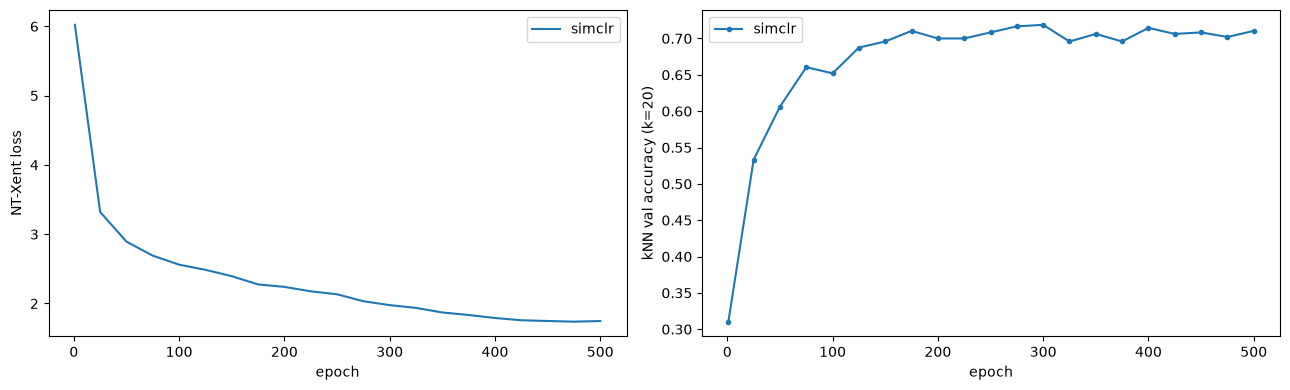

In [6]:
run('pretrain_ssl.py', 'simclr', 'simclr')
plots.ssl_curves(['simclr'], RUNS_DIR, save=FIGS / 'exp2_simclr_pretrain.png')

### Linear probe and fine-tuning

$ -u train.py --config configs/probe.yaml --name simclr_probe --set data_root=data runs_dir=runs init=runs/simclr/encoder.pt
Loaded encoder weights from runs/simclr/encoder.pt
simclr_probe | probe | resnet18 | 1920 labelled imgs | 1500 steps bs 256 | trainable 0.01M | aug={'scale_min': 1.0, 'scale_max': 1.0, 'flip': False, 'jitter': 0.0, 'hue': 0.0, 'jitter_p': 0.0, 'gray_p': 0.0}
time_s=5.1000  step=150  lr=0.0010  train_loss=0.7489  train_acc_aug=0.7999  train_loss_clean=0.3647  train_acc_clean=0.9010  val_loss=0.9021  val_acc=0.7417
time_s=9.6000  step=300  lr=0.0009  train_loss=0.2880  train_acc_aug=0.9304  train_loss_clean=0.2194  train_acc_clean=0.9557  val_loss=0.8259  val_acc=0.7333
time_s=14.2000  step=450  lr=0.0008  train_loss=0.1877  train_acc_aug=0.9681  train_loss_clean=0.1521  train_acc_clean=0.9833  val_loss=0.7994  val_acc=0.7313
time_s=18.7000  step=600  lr=0.0007  train_loss=0.1383  train_acc_aug=0.9846  train_loss_clean=0.1158  train_acc_clean=0.9906  val_loss=0.791

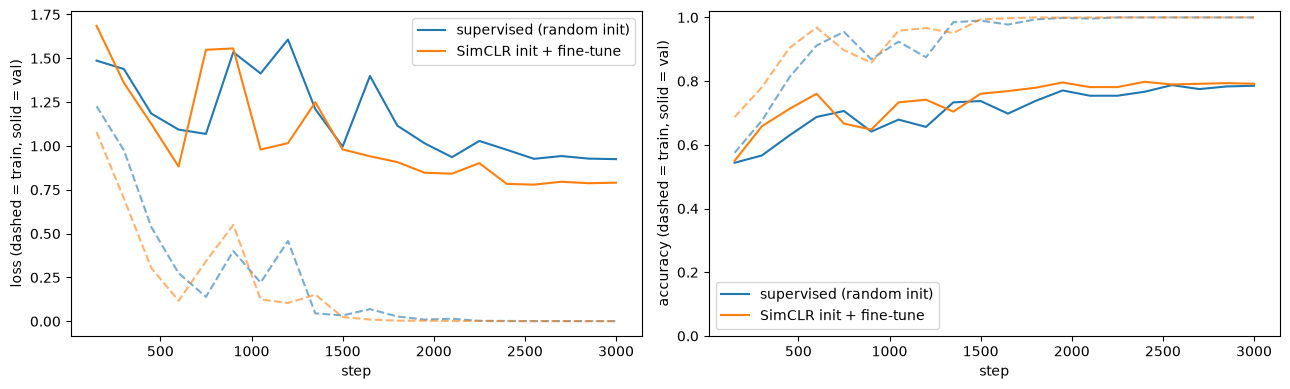

,labels,val,test,test+TTA,train(clean),gap,kNN val,min
method,,,,,,,,
sup_baseline,1920,78.5,76.0,75.5,100.0,21.5,-,8.3
simclr_probe,1920,72.1,72.5,71.7,99.9,27.9,-,0.8
simclr_ft,1920,79.2,75.5,75.7,100.0,20.8,-,8.2


In [7]:
ENC = (RUNS_DIR / 'simclr' / 'encoder.pt').as_posix()
run('train.py', 'probe', 'simclr_probe', f'init={ENC}')
run('train.py', 'finetune', 'simclr_ft', f'init={ENC}')
plots.curves(['sup_baseline', 'simclr_ft'], RUNS_DIR, labels=['supervised (random init)', 'SimCLR init + fine-tune'],
             save=FIGS / 'exp2_ft_vs_sup.png')
plots.table(['sup_baseline', 'simclr_probe', 'simclr_ft'], RUNS_DIR)

$ -u train.py --config configs/finetune.yaml --name simclr_ft_lowlr --set data_root=data runs_dir=runs init=runs/simclr/encoder.pt encoder_lr_mult=0.1
Loaded encoder weights from runs/simclr/encoder.pt
simclr_ft_lowlr | finetune | resnet18 | 1920 labelled imgs | 3000 steps bs 128 | trainable 11.18M | aug={'scale_min': 0.35, 'scale_max': 1.0, 'flip': True, 'jitter': 0.2, 'hue': 0.0, 'jitter_p': 0.8, 'gray_p': 0.0}
time_s=60.9000  step=150  lr=0.1000  train_loss=1.8182  train_acc_aug=0.6181  train_loss_clean=0.4032  train_acc_clean=0.8911  val_loss=0.7243  val_acc=0.7646
time_s=121.2000  step=300  lr=0.0993  train_loss=0.2201  train_acc_aug=0.9368  train_loss_clean=0.0642  train_acc_clean=0.9854  val_loss=0.7978  val_acc=0.7667
time_s=181.7000  step=450  lr=0.0973  train_loss=0.0735  train_acc_aug=0.9816  train_loss_clean=0.0306  train_acc_clean=0.9943  val_loss=0.7551  val_acc=0.7542
time_s=244.0000  step=600  lr=0.0940  train_loss=0.0455  train_acc_aug=0.9886  train_loss_clean=0.0145  

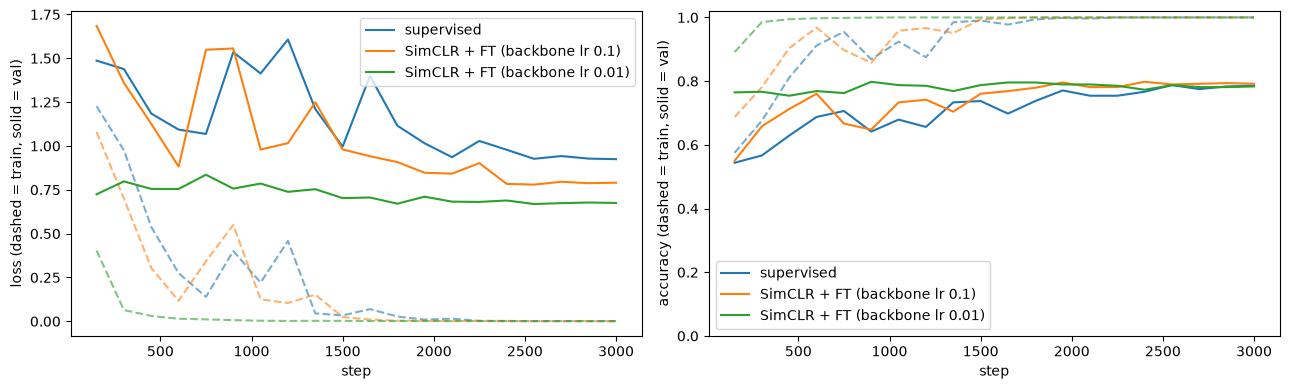

,labels,val,test,test+TTA,train(clean),gap,kNN val,min
method,,,,,,,,
sup_baseline,1920,78.5,76.0,75.5,100.0,21.5,-,8.3
simclr_probe,1920,72.1,72.5,71.7,99.9,27.9,-,0.8
simclr_ft,1920,79.2,75.5,75.7,100.0,20.8,-,8.2
simclr_ft_lowlr,1920,78.3,-,-,100.0,21.7,-,19.0


In [9]:
run('train.py', 'finetune', 'simclr_ft_lowlr', f'init={ENC}', 'encoder_lr_mult=0.1')
plots.curves(['sup_baseline', 'simclr_ft', 'simclr_ft_lowlr'], RUNS_DIR,
             labels=['supervised', 'SimCLR + FT (backbone lr 0.1)', 'SimCLR + FT (backbone lr 0.01)'],
             save=FIGS / 'exp2_ft_lr.png')
plots.table(['sup_baseline', 'simclr_probe', 'simclr_ft', 'simclr_ft_lowlr'], RUNS_DIR)

## 4. Joint CE + SimCLR, strong-augmentation supervised control

$ -u train.py --config configs/supervised_strongaug.yaml --name sup_strongaug --set data_root=data runs_dir=runs
[skip] sup_strongaug already has metrics.json (use --force to re-run)
$ -u train.py --config configs/joint.yaml --name joint --set data_root=data runs_dir=runs
joint | scratch+joint | resnet18 | 1920 labelled imgs | 3000 steps bs 128 | trainable 11.51M | aug={'scale_min': 0.2, 'scale_max': 1.0, 'flip': True, 'jitter': 0.4, 'hue': 0.1, 'jitter_p': 0.8, 'gray_p': 0.2}
time_s=47.6000  step=150  lr=0.1000  train_loss=1.9805  train_acc_aug=0.3603  train_loss_clean=1.1628  train_acc_clean=0.5891  val_loss=1.4437  val_acc=0.5292  ssl_loss=3.6463
time_s=94.9000  step=300  lr=0.0993  train_loss=0.9645  train_acc_aug=0.6800  train_loss_clean=1.3462  train_acc_clean=0.5828  val_loss=1.6868  val_acc=0.5000  ssl_loss=2.5562
time_s=142.1000  step=450  lr=0.0973  train_loss=0.6144  train_acc_aug=0.7923  train_loss_clean=0.3311  train_acc_clean=0.8781  val_loss=1.1377  val_acc=0.6750  ssl_l

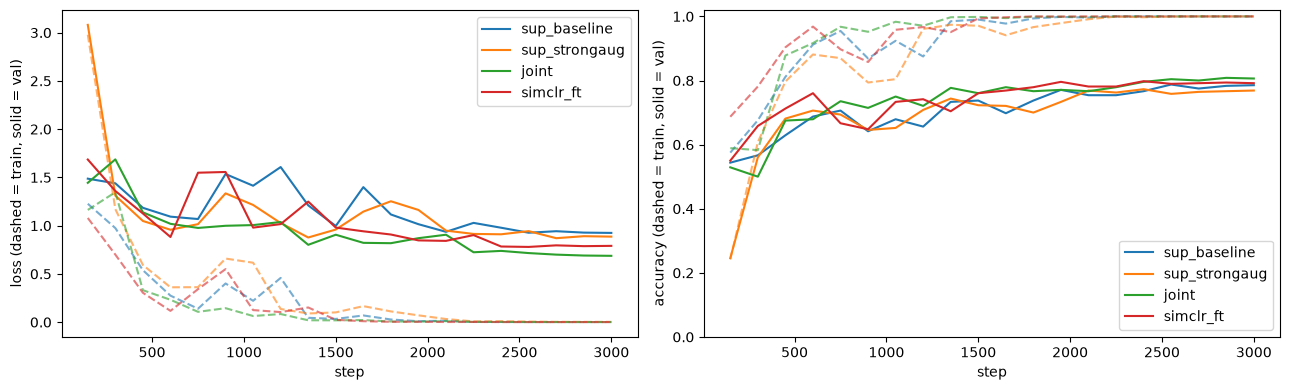

,labels,val,test,test+TTA,train(clean),gap,kNN val,min
method,,,,,,,,
sup_baseline,1920,78.5,76.0,75.5,100.0,21.5,-,8.3
sup_strongaug,1920,76.9,-,-,100.0,23.1,-,19.0
simclr_probe,1920,72.1,72.5,71.7,99.9,27.9,-,0.8
simclr_ft,1920,79.2,75.5,75.7,100.0,20.8,-,8.2
simclr_ft_lowlr,1920,78.3,-,-,100.0,21.7,-,19.0
joint,1920,80.6,-,-,100.0,19.4,-,16.7


In [8]:
run('train.py', 'supervised_strongaug', 'sup_strongaug')
run('train.py', 'joint', 'joint')
plots.curves(['sup_baseline', 'sup_strongaug', 'joint', 'simclr_ft'], RUNS_DIR, save=FIGS / 'exp3_joint.png')
plots.table(['sup_baseline', 'sup_strongaug', 'simclr_probe', 'simclr_ft', 'simclr_ft_lowlr', 'joint'], RUNS_DIR)

## 5. Label efficiency

In [15]:
FRACS = [0.1]
for f in FRACS:
    run('train.py', 'supervised', f'sup_frac{f}', f'label_frac={f}')
    run('train.py', 'finetune', f'ft_frac{f}', f'label_frac={f}', f'init={ENC}', 'encoder_lr_mult=0.1')
    run('train.py', 'probe', f'probe_frac{f}', f'label_frac={f}', f'init={ENC}')

$ -u train.py --config configs/supervised.yaml --name sup_frac0.1 --set data_root=data runs_dir=runs label_frac=0.1
sup_frac0.1 | scratch | resnet18 | 192 labelled imgs | 3000 steps bs 128 | trainable 11.18M | aug={'scale_min': 0.35, 'scale_max': 1.0, 'flip': True, 'jitter': 0.2, 'hue': 0.0, 'jitter_p': 0.8, 'gray_p': 0.0}
time_s=22.7000  step=150  lr=0.1000  train_loss=1.1018  train_acc_aug=0.6422  train_loss_clean=0.9356  train_acc_clean=0.8125  val_loss=4.6824  val_acc=0.3438
time_s=44.9000  step=300  lr=0.0993  train_loss=0.1393  train_acc_aug=0.9556  train_loss_clean=0.2347  train_acc_clean=0.9219  val_loss=3.5466  val_acc=0.4604
time_s=67.3000  step=450  lr=0.0973  train_loss=0.0641  train_acc_aug=0.9800  train_loss_clean=0.0288  train_acc_clean=0.9844  val_loss=4.2571  val_acc=0.4354
time_s=89.6000  step=600  lr=0.0940  train_loss=0.0351  train_acc_aug=0.9889  train_loss_clean=0.0427  train_acc_clean=0.9896  val_loss=3.7146  val_acc=0.4396
time_s=112.0000  step=750  lr=0.0895  t

KeyboardInterrupt: 

In [ ]:
import shutil
for a, b in [('sup_baseline', 'sup_frac1.0'), ('simclr_ft_lowlr', 'ft_frac1.0'), ('simclr_probe', 'probe_frac1.0')]:
    if (RUNS_DIR / a / 'metrics.json').exists() and not (RUNS_DIR / b).exists():
        shutil.copytree(RUNS_DIR / a, RUNS_DIR / b, ignore=shutil.ignore_patterns('*.pt'))
plots.label_efficiency({'supervised (random init)': 'sup_frac{f}', 'SimCLR + fine-tune': 'ft_frac{f}',
                        'SimCLR linear probe': 'probe_frac{f}'}, FRACS + [1.0], RUNS_DIR,
                       save=FIGS / 'exp4_label_efficiency.png')

## 6. Best recipe

$ -u train.py --config configs/finetune.yaml --name best --set data_root=data runs_dir=runs init=runs/simclr/encoder.pt encoder_lr_mult=0.1 mixup=0.2 cutmix=1.0 label_smoothing=0.1
Loaded encoder weights from runs/simclr/encoder.pt
best | finetune | resnet18 | 1920 labelled imgs | 3000 steps bs 128 | trainable 11.18M | aug={'scale_min': 0.35, 'scale_max': 1.0, 'flip': True, 'jitter': 0.2, 'hue': 0.0, 'jitter_p': 0.8, 'gray_p': 0.0}
time_s=61.3000  step=150  lr=0.1000  train_loss=2.3796  train_acc_aug=0.3465  train_loss_clean=0.7354  train_acc_clean=0.8427  val_loss=0.9723  val_acc=0.7729
time_s=123.1000  step=300  lr=0.0993  train_loss=1.4811  train_acc_aug=0.5445  train_loss_clean=0.3592  train_acc_clean=0.9479  val_loss=0.7966  val_acc=0.7896
time_s=185.5000  step=450  lr=0.0973  train_loss=1.3701  train_acc_aug=0.6239  train_loss_clean=0.2125  train_acc_clean=0.9911  val_loss=0.7659  val_acc=0.8042
time_s=248.2000  step=600  lr=0.0940  train_loss=1.3251  train_acc_aug=0.6336  train_

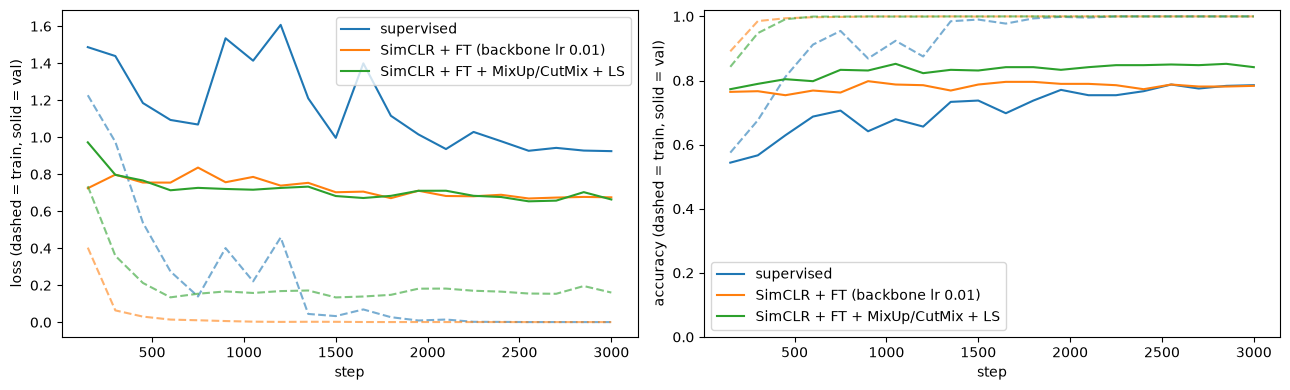

,labels,val,test,test+TTA,train(clean),gap,kNN val,min
method,,,,,,,,
sup_baseline,1920,78.5,76.0,75.5,100.0,21.5,-,8.3
simclr_ft_lowlr,1920,78.3,-,-,100.0,21.7,-,19.0
best,1920,84.2,-,-,100.0,15.8,-,15.6


In [16]:
REG = ['mixup=0.2', 'cutmix=1.0', 'label_smoothing=0.1']
run('train.py', 'finetune', 'best', f'init={ENC}', 'encoder_lr_mult=0.1', *REG)
plots.curves(['sup_baseline', 'simclr_ft_lowlr', 'best'], RUNS_DIR,
             labels=['supervised', 'SimCLR + FT (backbone lr 0.01)', 'SimCLR + FT + MixUp/CutMix + LS'],
             save=FIGS / 'best.png')
plots.table(['sup_baseline', 'simclr_ft_lowlr', 'best'], RUNS_DIR)

$ -u train.py --config configs/supervised.yaml --name sup_reg --set data_root=data runs_dir=runs mixup=0.2 cutmix=1.0 label_smoothing=0.1
sup_reg | scratch | resnet18 | 1920 labelled imgs | 3000 steps bs 128 | trainable 11.18M | aug={'scale_min': 0.35, 'scale_max': 1.0, 'flip': True, 'jitter': 0.2, 'hue': 0.0, 'jitter_p': 0.8, 'gray_p': 0.0}
time_s=24.5000  step=150  lr=0.1000  train_loss=2.4230  train_acc_aug=0.2203  train_loss_clean=1.5473  train_acc_clean=0.4849  val_loss=1.7118  val_acc=0.4542
time_s=48.9000  step=300  lr=0.0993  train_loss=1.8791  train_acc_aug=0.3929  train_loss_clean=1.0048  train_acc_clean=0.6865  val_loss=1.3049  val_acc=0.5750
time_s=73.4000  step=450  lr=0.0973  train_loss=1.7144  train_acc_aug=0.4883  train_loss_clean=0.6574  train_acc_clean=0.8547  val_loss=1.0427  val_acc=0.6875
time_s=98.0000  step=600  lr=0.0940  train_loss=1.6339  train_acc_aug=0.5074  train_loss_clean=0.6451  train_acc_clean=0.8281  val_loss=1.1066  val_acc=0.6563
time_s=122.5000  ste

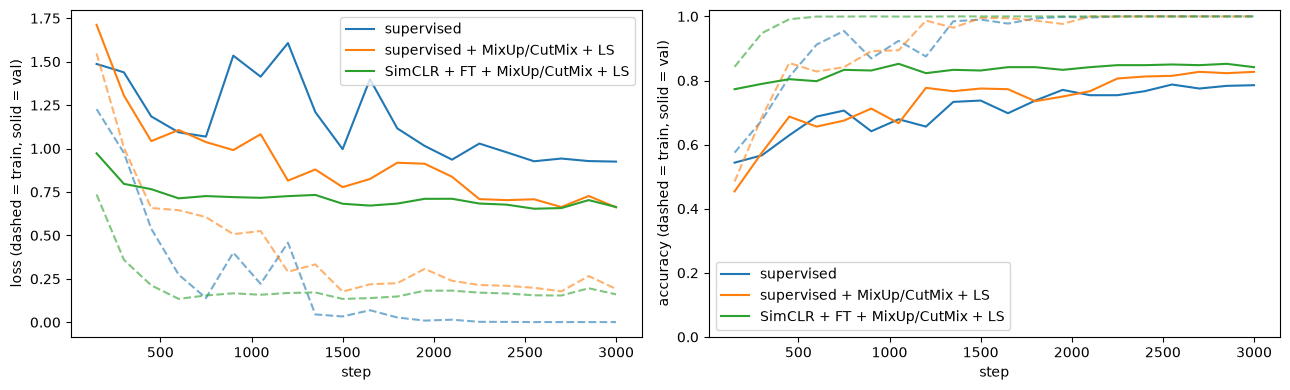

,labels,val,test,test+TTA,train(clean),gap,kNN val,min
method,,,,,,,,
sup_baseline,1920,78.5,76.0,75.5,100.0,21.5,-,8.3
sup_reg,1920,82.7,-,-,100.0,17.3,-,8.1
simclr_ft_lowlr,1920,78.3,-,-,100.0,21.7,-,19.0
best,1920,84.2,-,-,100.0,15.8,-,15.6


In [17]:
run('train.py', 'supervised', 'sup_reg', *REG)
plots.curves(['sup_baseline', 'sup_reg', 'best'], RUNS_DIR,
             labels=['supervised', 'supervised + MixUp/CutMix + LS', 'SimCLR + FT + MixUp/CutMix + LS'],
             save=FIGS / 'best_vs_sup_reg.png')
plots.table(['sup_baseline', 'sup_reg', 'simclr_ft_lowlr', 'best'], RUNS_DIR)

## 7. Test set evaluation

In [ ]:
FINAL = ['sup_baseline', 'sup_strongaug', 'simclr_probe', 'simclr_ft', 'simclr_ft_lowlr', 'joint', 'sup_reg', 'best']
cmd = [sys.executable, 'eval.py', '--data', (DATA_ROOT / 'test').as_posix(),
       '--run', *[(RUNS_DIR / n).as_posix() for n in FINAL if (RUNS_DIR / n / 'model.pt').exists()]]
r = subprocess.run(cmd, capture_output=True, text=True)
print(r.stdout, r.stderr)
r.check_returncode()

## 8. Summary

In [ ]:
plots.table(FINAL, RUNS_DIR,
            labels=['Supervised baseline', 'Supervised + SSL aug', 'SimCLR linear probe', 'SimCLR + fine-tune',
                    'SimCLR + fine-tune (backbone lr 0.01)', 'Joint CE + SimCLR', 'Supervised + MixUp/CutMix + LS',
                    'Best recipe'])